# DBAC main result: cooling performance vs. number of quantum instructions

This notebook reproduces the paper's main result (Fig. 4): double-bracket algorithmic
cooling (DBAC) implemented with a **Trotterized** DME subroutine (i.e. using a realistic,
finite number of Trotter steps $M$, unlike the idealized $M\to\infty$ limit studied in
[`sup_figure_S4.ipynb`](sup_figure_S4.ipynb)).

Three circuits are compared, all built from the same optimized step sizes cached in
`optimal_s_Mk.npy`:

| label  | Trotter steps $M$ | recursion depth $k$ | total qubits $n$ |
|--------|-------------------|----------------------|-------------------|
| $n=2$  | 1                 | 1                    | 2 (1 instruction) |
| $n=3$  | 2                 | 1                    | 3 (2 instructions)|
| $n=4$  | 1                 | 2                    | 4 (3 instructions)|

More total qubits means more copies of the state are consumed as "quantum instructions",
and the figures below show that this directly buys better cooling -- the central point of
the Nernst-principle-style trade-off discussed in the paper. The energy-vs-$\theta$ panels
are additionally compared against experimental data taken on a multicolor-driven
superconducting-qubit device.

All computation (the circuit definitions, the DB-QITE runs, and the digitized
experimental data) lives in
[`scripts/figure_4.py`](../scripts/figure_4.py); the plotting lives in
[`src/dbac/plotting/cooling.py`](../src/dbac/plotting/cooling.py).

In [1]:
%matplotlib inline
import sys
sys.path.append('..')
sys.path.append('../src')

import numpy as np

from config import plot_path
from dbac.plotting import use_paper_style, figure_size
from scripts.figure_4 import CIRCUITS, CIRCUIT_FILENAMES, EXPERIMENTAL_ENERGY, run_dbac_circuits
from dbac.gci import GCI
from dbac.dbqite import initial_psi
from dbac.utils import fidelity_with_0, rx_sweep

use_paper_style(font_size=10, figsize=figure_size("PRD", "onecol"))
optimal_s_Mk = np.load("optimal_s_Mk.npy")
thetas = np.linspace(0, 1, 100)

[Qibo 0.3.6|INFO|2026-10-22 12:42:37]: Using numpy backend on /CPU:0


## Fidelity-fidelity plot

Sweep the initial state over $R_X(\theta)|0\rangle$ and compare the fidelity with the
ground state before and after DB-QITE, for each circuit.

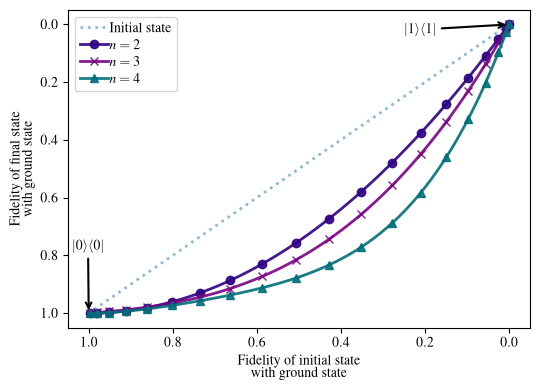

In [2]:
from dbac.plotting import plot_fidelity_fidelity

psis_fidelity = rx_sweep(thetas, start=np.array([[0], [1]], dtype=complex))
fidelities_initial = [fidelity_with_0(psi) for psi in psis_fidelity]
fid_results = run_dbac_circuits(psis_fidelity, optimal_s_Mk, as_fidelity=True)

plot_fidelity_fidelity(fidelities_initial, fidelities_initial, fid_results,
                      save_path=plot_path("F4_3_circuit_fid.pdf"));

## Energy vs. initialization angle $\theta$

Sweep the initial state over $R_X(\theta)|1\rangle$ instead (so the data-qubit *energy*,
rather than fidelity, varies monotonically and smoothly with $\theta$), and compare the
energy after DB-QITE to the un-cooled baseline.

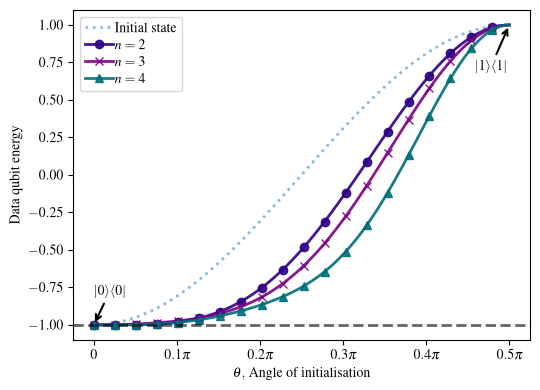

In [3]:
from dbac.plotting import plot_energy_vs_theta

psis_energy = rx_sweep(thetas, start=np.array([[1], [0]], dtype=complex))
theta_angles = thetas * np.pi / 2
res_init = [GCI(initial_psi, psi, 1, np.linspace(0.01, 1, 2)).execute_gci()[0][-1] for psi in psis_energy]
energy_results = run_dbac_circuits(psis_energy, optimal_s_Mk, as_fidelity=False)

xticks = np.linspace(0, np.pi / 2, 6)
xtick_labels = [r'$0$', r'$0.1\pi$', r'$0.2\pi$', r'$0.3\pi$', r'$0.4\pi$', r'$0.5\pi$']
plot_energy_vs_theta(theta_angles, res_init, energy_results, target_energy=-1,
                      xticks=xticks, xtick_labels=xtick_labels,
                      save_path=plot_path("F4_3_circuit_energy_theta.pdf"));

## Each circuit individually, overlaid with hardware experiment data

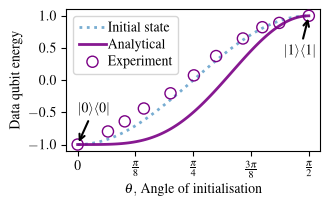

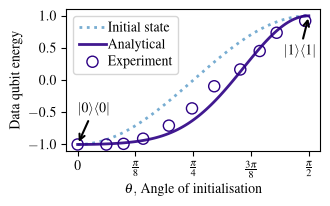

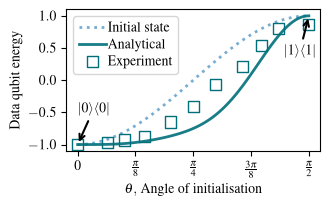

In [4]:
from dbac.plotting import plot_single_energy_curve

colors = ['#7a0085', '#2c0084', '#006f7a']
markers = ['o', 'o', 's']
small_xticks = [0, np.pi / 8, np.pi / 4, 3 * np.pi / 8, np.pi / 2]
small_xtick_labels = [r'$0$', r'$\frac{\pi}{8}$', r'$\frac{\pi}{4}$', r'$\frac{3\pi}{8}$', r'$\frac{\pi}{2}$']

for i, (label, curve) in enumerate(energy_results.items()):
    plot_single_energy_curve(theta_angles, res_init, label, curve, colors[i], markers[i],
                              experimental=EXPERIMENTAL_ENERGY.get(label),
                              xticks=small_xticks, xtick_labels=small_xtick_labels, show=True,
                              save_path=plot_path(CIRCUIT_FILENAMES[label]))